# ISS 915 MHz Wind Profiler — Curtain Plots

This notebook reads a daily Zarr store and
generates a three-panel time-height curtain plot:

1. **Signal-to-noise ratio** (dB) — from the `moments` group
2. **Vertical velocity** (m/s) — from the `moments` group
3. **Wind barbs** colored by wind speed (m/s) — from the `winds_reprocessed` or `winds_nima` group

**What is a Zarr store?**  
A Zarr store is a directory on disk that holds arrays and their metadata —
similar to a NetCDF file. The prof915 converter writes one Zarr store per day,
organized into three groups (`moments`, `winds_nima`, `winds_reprocessed`), one
per data product. Opening a group with `xr.open_zarr()` returns a standard
`xarray.Dataset` — from there it behaves exactly like data opened from NetCDF.

**How to use this notebook:**  
- Python backend dependencies require: aiohttp to allow xarray to read remote HTTPS Zarr stores.
- Run all cells in order.

In [49]:
%matplotlib inline
import os
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

import re
import requests
from urllib.parse import urljoin

In [50]:
# ----------------------------------------------------------------------------
# Returns .zarr stores from an HTTPS directory listing
# ----------------------------------------------------------------------------
def list_https_files(base_url, pattern=r'href="([^"?]+.zarr/?)'):
    r = requests.get(base_url, timeout=60)
    r.raise_for_status()
    return [urljoin(base_url, h) for h in re.findall(pattern, r.text)]

## 1. Configuration

In [51]:
# ----------------------------------------------------------------
# HTTPS configuration for accessing the 915 MHz Zarr dataset
# ----------------------------------------------------------------
# 915 MHz Dataset ID
DSID = "d361535"

# Method: HTTPS Web File Listing
HTTPS_BASE = f"https://osdf-director.osg-htc.org/ncar/gdex/{DSID}/zarr/"

# List all Zarr stores available at the HTTPS base URL
url = list_https_files(HTTPS_BASE)

# Check that we have found the Zarr stores
if not url:
    raise ValueError("No Zarr stores found at the specified HTTPS base URL.")
print(f"Found {len(url)} Zarr stores.")

# Note the beginning date and end date from the file names
begin_date = min(url)
end_date = max(url)
print(f"Beginning file: {os.path.basename(begin_date.rstrip('/'))}")
print(f"End file: {os.path.basename(end_date.rstrip('/'))}")


Found 61 Zarr stores.
Beginning file: m2hats_eol-iss_windradar_915MHz_20230725_v1.zarr
End file: m2hats_eol-iss_windradar_915MHz_20230924_v1.zarr


In [52]:
# ------------------------------------------------------------------------------------------------
# Edit the values below before running. 
# 'WINDS_GROUP` selects whether to use the winds_reprocessed or winds_nima for panel 3.
# The time range options let you zoom into a subset of the day. 
# ------------------------------------------------------------------------------------------------
DATE        = '20230909'        # YYYYMMDD
CAMPAIGN     = 'M2HATS'
WINDS_GROUP = 'winds_nima'      # group used for winds and barbs panel
                                # NOTE: 'winds_nima' has no 'u'/'v'; use u_classicC/v_classicC instead

# Get the Zarr store URL for the current date
ZARR_STORE = f"{HTTPS_BASE}{CAMPAIGN.lower()}_eol-iss_windradar_915MHz_{DATE}_v1.zarr"

# Time range — set ONE option; leave others as None for a full-day plot
PLOT_HOURS  = None     # last N hours from end of file (e.g. 4 or 10)
PLOT_START  = None     # explicit start string, e.g. '2023-08-01 12:00'
PLOT_END    = None     # explicit end   string, e.g. '2023-08-01 16:30'

# Color limits
SNR_VMIN, SNR_VMAX = -20, 20   # sigNoiseRatio [dB]
VEL_VMAX           =  10       # vertical velocity [m/s], symmetric ±
WSPD_VMAX          =  15       # wind speed background [m/s]

# Output
OUTPUT_DIR  = 'Full path to output directory'
SAVE_FIGURE = False   # True = save PNG to OUTPUT_DIR; False = display inline

## 2. Opening the Zarr store

The daily store contains three groups:
- `moments` — Doppler data (~3944 time steps per day, one per radar dwell)
- `winds_reprocessed` or `winds_nima` — 30-minute averaged winds (48 time steps per day)

`consolidated=True` reads the single `.zmetadata` summary file at the store root
rather than opening each variable's metadata file one by one — faster, especially
over a networked filesystem. 

The `height` coordinate is 2-D `(time, height)` in all groups. Heights are constant
across time for this instrument, so `height[0, :]` gives a representative 1-D
height vector suitable for the y-axis.

In [53]:
# Open both groups — each returns a standard xarray Dataset
ds_mom   = xr.open_zarr(ZARR_STORE, group='moments',   consolidated=True)
ds_winds = xr.open_zarr(ZARR_STORE, group=WINDS_GROUP, consolidated=True)

# Apply optional time range filter
if PLOT_HOURS is not None:
    t_end   = ds_mom['time'].values[-1]
    t_start = t_end - np.timedelta64(int(PLOT_HOURS * 3600), 's')
    ds_mom   = ds_mom.sel(time=slice(t_start, t_end))
    ds_winds = ds_winds.sel(time=slice(t_start, t_end))
elif PLOT_START is not None and PLOT_END is not None:
    ds_mom   = ds_mom.sel(time=slice(np.datetime64(PLOT_START), np.datetime64(PLOT_END)))
    ds_winds = ds_winds.sel(time=slice(np.datetime64(PLOT_START), np.datetime64(PLOT_END)))

## 3. Plotting the curtain

A **curtain plot** stacks time along the x-axis and height along the y-axis,
showing how a variable evolves through the day at each altitude level.
`pcolormesh` draws the filled color grid; wind barbs are overlaid on panel 3
using subsampled `u` and `v` components converted from m/s to knots (the
meteorological convention for barb plots).

The moments group has ~3944 time steps and the winds group has 48 — they use
separate time arrays but share the same x-axis via `sharex=True`. `pcolormesh`
handles the different resolutions correctly because each panel passes its own
time array. 

Wind barbs are subsampled to ~60 time × 15 height points for readability — the
full-resolution data would produce an unreadable dense grid of barbs.

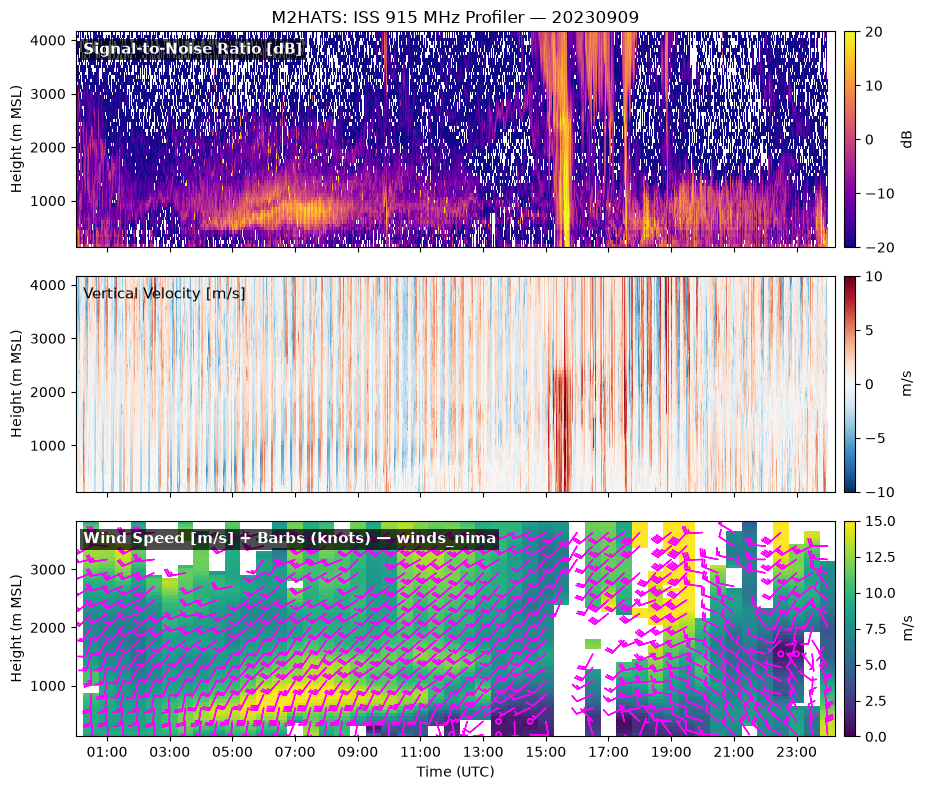

In [54]:
# Extract arrays — height is 2-D (time, height); use first time step as representative 1-D vector
time_mom   = ds_mom['time'].values
height_mom = ds_mom['height'].values[0, :]
snr        = ds_mom['sigNoiseRatio'].values   # (time, height)
vel        = ds_mom['vel'].values             # (time, height)

time_w     = ds_winds['time'].values
height_w   = ds_winds['height'].values[0, :]
wspd       = ds_winds['wspd'].values          # (time, height), m/s

# Use wind components by group and correct convention for reprocessed winds.
if WINDS_GROUP == 'winds_nima':
    u = ds_winds['u_classicC'].values
    v = ds_winds['v_classicC'].values
elif WINDS_GROUP == 'winds_reprocessed':
    # Reprocessed u/v are opposite the wind-from convention used by matplotlib barbs.
    u = -ds_winds['u'].values
    v = -ds_winds['v'].values
else:
    u = ds_winds['u'].values
    v = ds_winds['v'].values

# Wind barb subsampling — target ~60 time × 15 height points regardless of resolution
n_time_winds, n_height_winds = u.shape
t_step   = max(1, n_time_winds   // 60)
h_step   = max(1, n_height_winds // 15)

# [::t_step] takes every t_step-th element along that axis
# [::h_step] takes every h_step-th element along that axis
time_sub   = time_w[::t_step]
height_sub = height_w[::h_step]
u_sub      = u[::t_step, ::h_step]
v_sub      = v[::t_step, ::h_step]

# Convert u, v from m/s to knots — meteorological convention for wind barbs
MS_TO_KNOTS = 1.94384
u_kts      = (u_sub * MS_TO_KNOTS)
v_kts      = (v_sub * MS_TO_KNOTS)
# Repeat time and height values across height columns and time rows to create a 2-D grid for wind barb plotting
T_grid, H_grid       = np.meshgrid(time_sub, height_sub, indexing='ij')

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.subplots_adjust(hspace=0.06)

# Panel 1 — Signal-to-noise ratio
# The transpose is important: the snr array is shaped [time, height], 
# but pcolormesh expects [y, x] = [height, time], so .T flips it to align with axes.
pc1 = axes[0].pcolormesh(time_mom, height_mom, snr.T,
                          cmap='plasma', vmin=SNR_VMIN, vmax=SNR_VMAX, shading='auto')
fig.colorbar(pc1, ax=axes[0], label='dB', pad=0.01)
axes[0].set_ylabel('Height (m MSL)')
axes[0].set_title(f'{CAMPAIGN}: ISS 915 MHz Profiler — {DATE}', fontsize=12)
bbox=dict(facecolor='black', alpha=0.7, pad=2, edgecolor='none')
axes[0].text(0.01, 0.95, 'Signal-to-Noise Ratio [dB]', transform=axes[0].transAxes,
             va='top', fontsize=11, fontweight='bold', color='white', bbox=bbox)

# Panel 2 — vertical velocity
pc2 = axes[1].pcolormesh(time_mom, height_mom, vel.T,
                          cmap='RdBu_r', vmin=-VEL_VMAX, vmax=VEL_VMAX, shading='auto')
fig.colorbar(pc2, ax=axes[1], label='m/s', pad=0.01)
axes[1].set_ylabel('Height (m MSL)')
axes[1].text(0.01, 0.95, 'Vertical Velocity [m/s]', transform=axes[1].transAxes,
             va='top', fontsize=11)

# Panel 3 — Wind speed background + wind barbs (barbs in knots; background in m/s)
pc3 = axes[2].pcolormesh(time_w, height_w, wspd.T,
                          cmap='viridis', vmin=0, vmax=WSPD_VMAX, shading='auto')
fig.colorbar(pc3, ax=axes[2], label='m/s', pad=0.01)
axes[2].barbs(T_grid.flatten(), H_grid.flatten(), u_kts.flatten(), v_kts.flatten(), length=5, linewidth=1, color='magenta')
axes[2].set_ylabel('Height (m MSL)')
axes[2].set_xlabel('Time (UTC)')
axes[2].text(0.01, 0.95, f'Wind Speed [m/s] + Barbs (knots) — {WINDS_GROUP}', 
             transform=axes[2].transAxes,
             va='top', fontsize=11, fontweight='bold', color='white', bbox=bbox)


# Shared x-axis formatting applied to bottom panel only
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
axes[2].xaxis.set_major_locator(mdates.HourLocator(interval=2))
fig.autofmt_xdate(rotation=0, ha='center')

fig.tight_layout()

if SAVE_FIGURE:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    out_path = os.path.join(OUTPUT_DIR, f'{CAMPAIGN}_prof915_{DATE}_curtain.png')
    fig.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f'Saved: {out_path}')
else:
    plt.show()